# 03_LSTM — NASA C-MAPSS FD001

**Project:** Remaining Useful Life Prediction for Turbofan Engines Using XGBoost and LSTM  
**Dataset:** NASA C-MAPSS FD001  
**Framework:** PyTorch

This notebook trains the LSTM model.

I use:
- the same FD001 data
- the same engine-level validation split as XGBoost
- an RUL cap of 125 cycles
- 30-cycle input sequences
- 18 input features per cycle
- three random seeds
- RMSE and MAE as the main measures


## 1. Imports

This notebook uses PyTorch for the LSTM and scikit-learn for scaling and evaluation.

The model is run on CPU in this notebook.


In [1]:
from pathlib import Path
import copy
import json
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.12.0.dev20260408+cu128
CUDA available: True


## 2. Settings

The sequence length is **30 cycles**.

The model uses **64 hidden units**, dropout of **0.20**, batch size **256** and learning rate **0.001**.


In [2]:
RUL_CAP = 125
SEQUENCE_LENGTH = 30

HIDDEN_SIZE = 64
DROPOUT = 0.20
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 60
EARLY_STOPPING_PATIENCE = 8

# Run the model with three random seeds.
SEEDS = [42, 7, 123]

# Use one seed for a quick test.
# Use all three seeds for the full run.

OUTPUT_DIR = Path("lstm_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cpu")

print("Device:", DEVICE)
print("Sequence length:", SEQUENCE_LENGTH)
print("RUL cap:", RUL_CAP)
print("Seeds:", SEEDS)

Device: cpu
Sequence length: 30
RUL cap: 125
Seeds: [42, 7, 123]


## 3. Random seeds

I run the LSTM three times with seeds **42, 7 and 123**.

This lets me see how much the result changes between runs.


In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if DEVICE.type == "cuda":
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass

## 4. Load the FD001 files

The notebook loads:

- `train_FD001.txt`
- `test_FD001.txt`
- `RUL_FD001.txt`


In [4]:
def resolve_file(filename):
    local = Path(filename)
    if local.exists():
        return local

    alt = Path("/mnt/data") / filename
    if alt.exists():
        return alt

    raise FileNotFoundError(
        f"{filename} was not found. Put it in the same folder as this notebook."
    )


TRAIN_PATH = resolve_file("train_FD001.txt")
TEST_PATH = resolve_file("test_FD001.txt")
RUL_PATH = resolve_file("RUL_FD001.txt")

columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(TRAIN_PATH, sep=r"\s+", header=None, names=columns)
test = pd.read_csv(TEST_PATH, sep=r"\s+", header=None, names=columns)
test_rul = pd.read_csv(RUL_PATH, sep=r"\s+", header=None, names=["RUL"])

print("Training shape:", train.shape)
print("Test shape:    ", test.shape)
print("RUL shape:     ", test_rul.shape)

Training shape: (20631, 26)
Test shape:     (13096, 26)
RUL shape:      (100, 1)


## 5. Create the training RUL

I calculate RUL from the last cycle of each training engine and cap the training target at **125 cycles**.


In [5]:
train_model = train.copy()

max_cycle = train_model.groupby("unit")["cycle"].transform("max")
train_model["RUL_raw"] = max_cycle - train_model["cycle"]
train_model["RUL"] = train_model["RUL_raw"].clip(upper=RUL_CAP)

display(train_model[["unit", "cycle", "RUL_raw", "RUL"]].head(10))

final_rows = train_model.loc[
    train_model.groupby("unit")["cycle"].idxmax()
]

print("Final-cycle RUL values:", sorted(final_rows["RUL_raw"].unique()))

,unit,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


Final-cycle RUL values: [np.int64(0)]


## 6. Remove constant columns

I remove the same constant columns found during EDA.

The LSTM uses **18 features** at each time step: cycle, two operating settings and 15 sensors.


In [6]:
constant_columns = [
    c for c in columns
    if train_model[c].nunique(dropna=False) == 1
]

print("Constant columns:")
for c in constant_columns:
    print("-", c)

sequence_features = [
    c for c in columns
    if c != "unit" and c not in constant_columns
]

print("\nSequence feature count:", len(sequence_features))
print(sequence_features)

Constant columns:
- op_setting_3
- sensor_1
- sensor_5
- sensor_10
- sensor_16
- sensor_18
- sensor_19

Sequence feature count: 18
['cycle', 'op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 7. Use the same validation engines as XGBoost

I use exactly the same 20 validation engines as the XGBoost notebook.

This keeps the comparison consistent.


In [7]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

fit_idx, val_idx = next(
    splitter.split(
        train_model,
        train_model["RUL"],
        groups=train_model["unit"]
    )
)

fit_df = train_model.iloc[fit_idx].copy()
val_df = train_model.iloc[val_idx].copy()

fit_engines = sorted(int(x) for x in fit_df["unit"].unique())
val_engines = sorted(int(x) for x in val_df["unit"].unique())

EXPECTED_VAL_ENGINES = [
    1, 5, 11, 13, 19, 23, 31, 32, 34, 40,
    45, 46, 54, 71, 74, 77, 78, 81, 84, 91
]

print("Training engines:", len(fit_engines))
print("Validation engines:", len(val_engines))
print("Overlap:", set(fit_engines).intersection(val_engines))
print("Validation engine IDs:", val_engines)

assert set(fit_engines).isdisjoint(val_engines)
assert val_engines == EXPECTED_VAL_ENGINES, (
    "Validation engines differ from the completed XGBoost notebook. "
    "Check the split before continuing."
)

print("\nSplit matches 02_XGBoost.ipynb.")

Training engines: 80
Validation engines: 20
Overlap: set()
Validation engine IDs: [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]

Split matches 02_XGBoost.ipynb.


## 8. Scale the inputs

I fit the scaler using the training engines only.

I then use the same scaler on the validation and test data.


In [8]:
scaler = StandardScaler()

scaler.fit(fit_df[sequence_features])

fit_scaled = fit_df.copy()
val_scaled = val_df.copy()
test_scaled = test.copy()

fit_scaled[sequence_features] = scaler.transform(
    fit_df[sequence_features]
)

val_scaled[sequence_features] = scaler.transform(
    val_df[sequence_features]
)

test_scaled[sequence_features] = scaler.transform(
    test[sequence_features]
)

print("Scaler fitted using rows from training engines only.")
print("Scaled feature count:", len(sequence_features))

Scaler fitted using rows from training engines only.
Scaled feature count: 18


## 9. Create sequences

Each input contains **30 consecutive cycles** from one engine.

The RUL at the last cycle of the sequence is the target.


In [9]:
def make_sequences(df, feature_cols, sequence_length=30):
    sequences = []
    targets = []
    units = []
    end_cycles = []

    for unit_id, group in df.groupby("unit"):
        group = group.sort_values("cycle")

        x = group[feature_cols].to_numpy(dtype=np.float32)
        y = group["RUL"].to_numpy(dtype=np.float32)
        cycles = group["cycle"].to_numpy()

        for end in range(sequence_length - 1, len(group)):
            start = end - sequence_length + 1

            sequences.append(x[start:end + 1])
            targets.append(y[end])
            units.append(int(unit_id))
            end_cycles.append(int(cycles[end]))

    return (
        np.asarray(sequences, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
        np.asarray(units),
        np.asarray(end_cycles),
    )


X_fit, y_fit, fit_seq_units, fit_seq_cycles = make_sequences(
    fit_scaled,
    sequence_features,
    SEQUENCE_LENGTH
)

X_val, y_val, val_seq_units, val_seq_cycles = make_sequences(
    val_scaled,
    sequence_features,
    SEQUENCE_LENGTH
)

print("Training sequences:", X_fit.shape)
print("Validation sequences:", X_val.shape)
print("Training targets:", y_fit.shape)
print("Validation targets:", y_val.shape)

Training sequences: (14241, 30, 18)
Validation sequences: (3490, 30, 18)
Training targets: (14241,)
Validation targets: (3490,)


In [10]:
assert X_fit.ndim == 3
assert X_val.ndim == 3
assert X_fit.shape[1] == SEQUENCE_LENGTH
assert X_fit.shape[2] == len(sequence_features)
assert not np.isnan(X_fit).any()
assert not np.isnan(X_val).any()

print("Sequence sanity checks passed.")

Sequence sanity checks passed.


## 10. Create the final test sequence

For each test engine I use its last 30 cycles.

The sequence values are scaled for the LSTM, but the displayed `last_observed_cycle` is taken from the original unscaled test data.


In [11]:
def make_test_final_sequences(df, feature_cols, sequence_length=30):
    sequences = []
    units = []
    last_cycles = []

    for unit_id, group in df.groupby("unit"):
        group = group.sort_values("cycle")
        x = group[feature_cols].to_numpy(dtype=np.float32)

        if len(x) >= sequence_length:
            seq = x[-sequence_length:]
        else:
            pad_count = sequence_length - len(x)
            padding = np.repeat(x[[0]], pad_count, axis=0)
            seq = np.concatenate([padding, x], axis=0)

        sequences.append(seq)
        units.append(int(unit_id))
        last_cycles.append(int(group["cycle"].iloc[-1]))

    return (
        np.asarray(sequences, dtype=np.float32),
        np.asarray(units),
        np.asarray(last_cycles),
    )


X_test, test_units, test_last_cycles = make_test_final_sequences(
    test_scaled,
    sequence_features,
    SEQUENCE_LENGTH
)

# Keep the real cycle numbers for reporting.
# The cycle values inside X_test stay scaled because they are model inputs.
test_last_cycles = (
    test.groupby("unit")["cycle"]
    .max()
    .sort_index()
    .to_numpy(dtype=int)
)

y_test = test_rul["RUL"].to_numpy(dtype=np.float32)

print("Official test sequences:", X_test.shape)
print("Official test targets:", y_test.shape)

assert len(X_test) == 100
assert len(y_test) == 100

Official test sequences: (100, 30, 18)
Official test targets: (100,)


## 11. Convert the data to PyTorch tensors


In [12]:
X_fit_tensor = torch.tensor(X_fit, dtype=torch.float32)
y_fit_tensor = torch.tensor(y_fit, dtype=torch.float32).view(-1, 1)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

print("Training tensor:", X_fit_tensor.shape)
print("Validation tensor:", X_val_tensor.shape)
print("Test tensor:", X_test_tensor.shape)

Training tensor: torch.Size([14241, 30, 18])
Validation tensor: torch.Size([3490, 30, 18])
Test tensor: torch.Size([100, 30, 18])


## 12. LSTM model

The model has:
- one LSTM layer
- 64 hidden units
- dropout
- one output value for RUL

The model has **21,569 trainable parameters**.


In [13]:
class RULLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64, dropout=0.2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)

        last_hidden = sequence_output[:, -1, :]
        last_hidden = self.dropout(last_hidden)

        prediction = self.output(last_hidden)
        return prediction


example_model = RULLSTM(
    input_size=len(sequence_features),
    hidden_size=HIDDEN_SIZE,
    dropout=DROPOUT
)

print(example_model)

trainable_parameters = sum(
    p.numel() for p in example_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_parameters)

RULLSTM(
  (lstm): LSTM(18, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 21569


## 13. Evaluation functions

These functions calculate RMSE, MAE, R² and the NASA score.


In [14]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


def nasa_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    errors = y_pred - y_true

    penalties = np.where(
        errors < 0,
        np.exp(-errors / 13.0) - 1.0,
        np.exp(errors / 10.0) - 1.0
    )

    return float(np.sum(penalties))


@torch.no_grad()
def predict_tensor(model, tensor, batch_size=512):
    model.eval()

    predictions = []

    loader = DataLoader(
        TensorDataset(tensor),
        batch_size=batch_size,
        shuffle=False
    )

    for (xb,) in loader:
        xb = xb.to(DEVICE)
        pred = model(xb)
        predictions.append(pred.cpu().numpy().reshape(-1))

    result = np.concatenate(predictions)
    return np.maximum(result, 0.0)

## 14. Train with early stopping

I train with MSE loss and the Adam optimiser.

After each epoch I check validation RMSE and keep the best model state.


In [15]:
def train_one_seed(seed):
    set_seed(seed)

    train_dataset = TensorDataset(
        X_fit_tensor,
        y_fit_tensor
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    model = RULLSTM(
        input_size=len(sequence_features),
        hidden_size=HIDDEN_SIZE,
        dropout=DROPOUT
    ).to(DEVICE)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    history = {
        "train_mse": [],
        "val_rmse": [],
        "val_mae": []
    }

    best_state = None
    best_val_rmse = np.inf
    best_epoch = None
    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()

        running_loss = 0.0
        sample_count = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            pred = model(xb)
            loss = criterion(pred, yb)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            batch_size = xb.size(0)
            running_loss += loss.item() * batch_size
            sample_count += batch_size

        train_mse = running_loss / sample_count

        val_pred = predict_tensor(model, X_val_tensor)
        val_metrics = regression_metrics(y_val, val_pred)

        history["train_mse"].append(train_mse)
        history["val_rmse"].append(val_metrics["RMSE"])
        history["val_mae"].append(val_metrics["MAE"])

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"Train MSE {train_mse:.4f} | "
            f"Val RMSE {val_metrics['RMSE']:.4f} | "
            f"Val MAE {val_metrics['MAE']:.4f}"
        )

        if val_metrics["RMSE"] < best_val_rmse - 1e-4:
            best_val_rmse = val_metrics["RMSE"]
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(
                f"Early stopping for seed {seed} "
                f"at epoch {epoch}."
            )
            break

    training_seconds = time.time() - start_time

    model.load_state_dict(best_state)

    # Calculate results using the best saved model.
    val_pred = predict_tensor(model, X_val_tensor)
    test_pred = predict_tensor(model, X_test_tensor)

    val_metrics = regression_metrics(y_val, val_pred)
    test_metrics = regression_metrics(y_test, test_pred)
    test_metrics["NASA_score"] = nasa_score(y_test, test_pred)

    return {
        "seed": seed,
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "training_seconds": training_seconds,
        "val_pred": val_pred,
        "test_pred": test_pred,
        "val_metrics": val_metrics,
        "test_metrics": test_metrics
    }

## 15. Run the three seeds

The full experiment uses:

`SEEDS = [42, 7, 123]`

Each seed starts a separate LSTM training run.


In [16]:
all_runs = []

for seed in SEEDS:
    print("\n" + "=" * 75)
    print(f"STARTING LSTM RUN WITH SEED {seed}")
    print("=" * 75)

    result = train_one_seed(seed)
    all_runs.append(result)

    model_path = OUTPUT_DIR / f"lstm_fd001_seed_{seed}.pt"

    torch.save(
        {
            "model_state_dict": result["model"].state_dict(),
            "seed": seed,
            "sequence_length": SEQUENCE_LENGTH,
            "input_features": sequence_features,
            "hidden_size": HIDDEN_SIZE,
            "dropout": DROPOUT,
            "rul_cap": RUL_CAP,
        },
        model_path
    )

    print(
        f"Seed {seed} test RMSE: "
        f"{result['test_metrics']['RMSE']:.4f}"
    )
    print(
        f"Seed {seed} test MAE:  "
        f"{result['test_metrics']['MAE']:.4f}"
    )

print("\nAll requested LSTM runs completed.")


STARTING LSTM RUN WITH SEED 42
Seed 42 | Epoch 01 | Train MSE 7898.5822 | Val RMSE 84.7890 | Val MAE 74.1896
Seed 42 | Epoch 02 | Train MSE 6992.5014 | Val RMSE 80.9690 | Val MAE 70.0727
Seed 42 | Epoch 03 | Train MSE 6422.2190 | Val RMSE 77.6764 | Val MAE 66.6511
Seed 42 | Epoch 04 | Train MSE 5912.4766 | Val RMSE 74.5244 | Val MAE 63.4767
Seed 42 | Epoch 05 | Train MSE 5443.5245 | Val RMSE 71.4178 | Val MAE 60.1145
Seed 42 | Epoch 06 | Train MSE 5000.9454 | Val RMSE 68.3861 | Val MAE 57.0445
Seed 42 | Epoch 07 | Train MSE 4585.7385 | Val RMSE 65.4079 | Val MAE 54.1055
Seed 42 | Epoch 08 | Train MSE 4192.0074 | Val RMSE 62.4683 | Val MAE 51.1693
Seed 42 | Epoch 09 | Train MSE 3820.6362 | Val RMSE 59.5841 | Val MAE 48.3523
Seed 42 | Epoch 10 | Train MSE 3470.5421 | Val RMSE 56.7605 | Val MAE 45.7237
Seed 42 | Epoch 11 | Train MSE 3151.9306 | Val RMSE 53.9882 | Val MAE 43.0617
Seed 42 | Epoch 12 | Train MSE 2852.4612 | Val RMSE 51.3054 | Val MAE 40.6693
Seed 42 | Epoch 13 | Train MSE 2

## 16. Result for each seed

This table shows the best epoch and the validation/test result for each run.


In [17]:
seed_results = []

for run in all_runs:
    seed_results.append({
        "seed": run["seed"],
        "best_epoch": run["best_epoch"],
        "training_seconds": run["training_seconds"],
        "validation_RMSE": run["val_metrics"]["RMSE"],
        "validation_MAE": run["val_metrics"]["MAE"],
        "validation_R2": run["val_metrics"]["R2"],
        "test_RMSE": run["test_metrics"]["RMSE"],
        "test_MAE": run["test_metrics"]["MAE"],
        "test_R2": run["test_metrics"]["R2"],
        "test_NASA_score": run["test_metrics"]["NASA_score"],
    })

seed_results = pd.DataFrame(seed_results)

display(seed_results)

,seed,best_epoch,training_seconds,validation_RMSE,validation_MAE,validation_R2,test_RMSE,test_MAE,test_R2,test_NASA_score
0,42,52,36.160590,14.139985,10.803336,0.885315,16.150158,11.514963,0.848959,437.345154
1,7,57,37.466089,15.058755,10.907627,0.869927,17.119609,12.252624,0.830282,426.398193
2,123,50,43.625491,14.443641,11.270892,0.880336,14.913294,10.768789,0.871208,346.386719


## 17. Average result

I calculate the mean and standard deviation across the three LSTM runs.


In [18]:
summary_metrics = pd.DataFrame({
    "Metric": [
        "Test RMSE",
        "Test MAE",
        "Test R2",
        "NASA score"
    ],
    "Mean": [
        seed_results["test_RMSE"].mean(),
        seed_results["test_MAE"].mean(),
        seed_results["test_R2"].mean(),
        seed_results["test_NASA_score"].mean()
    ],
    "Std": [
        seed_results["test_RMSE"].std(ddof=1) if len(seed_results) > 1 else np.nan,
        seed_results["test_MAE"].std(ddof=1) if len(seed_results) > 1 else np.nan,
        seed_results["test_R2"].std(ddof=1) if len(seed_results) > 1 else np.nan,
        seed_results["test_NASA_score"].std(ddof=1) if len(seed_results) > 1 else np.nan
    ]
})

display(summary_metrics)

print(
    "Mean test RMSE:",
    round(seed_results["test_RMSE"].mean(), 4)
)
print(
    "Mean test MAE:",
    round(seed_results["test_MAE"].mean(), 4)
)

,Metric,Mean,Std
0,Test RMSE,16.061021,1.105855
1,Test MAE,11.512125,0.741921
2,Test R2,0.850150,0.020489
3,NASA score,403.376689,49.657341


Mean test RMSE: 16.061
Mean test MAE: 11.5121


## 18. Training history

These plots show the validation error for each seed.


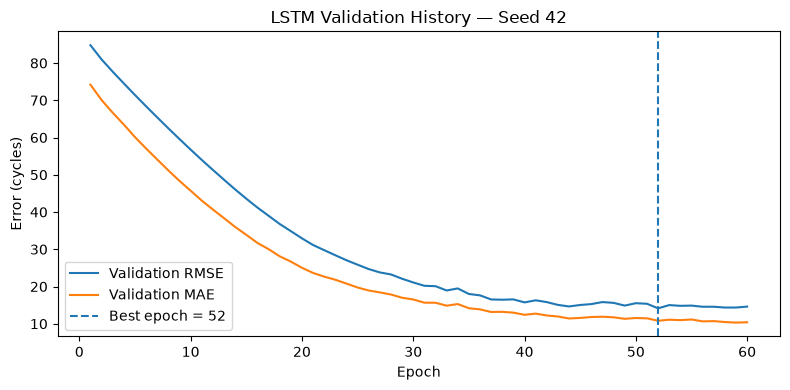

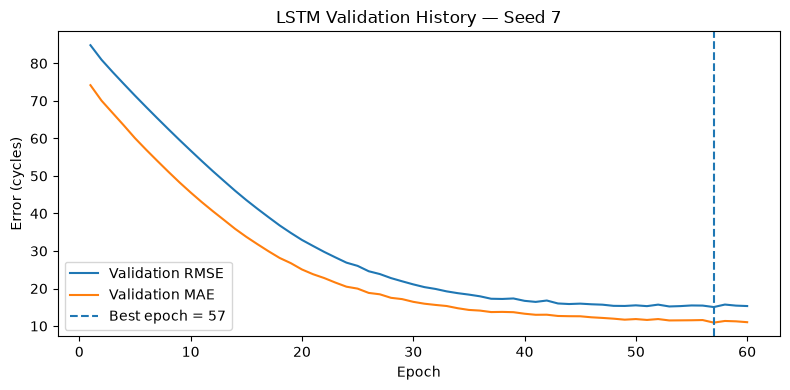

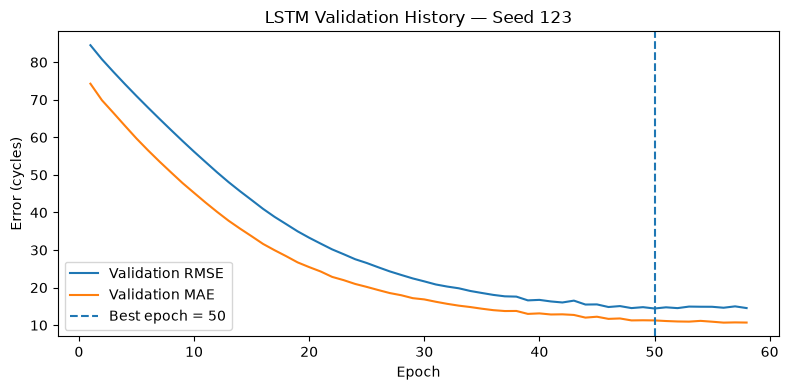

In [19]:
for run in all_runs:
    epochs = np.arange(
        1,
        len(run["history"]["val_rmse"]) + 1
    )

    plt.figure(figsize=(8, 4))
    plt.plot(
        epochs,
        run["history"]["val_rmse"],
        label="Validation RMSE"
    )
    plt.plot(
        epochs,
        run["history"]["val_mae"],
        label="Validation MAE"
    )
    plt.axvline(
        run["best_epoch"],
        linestyle="--",
        label=f"Best epoch = {run['best_epoch']}"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Error (cycles)")
    plt.title(
        f"LSTM Validation History — Seed {run['seed']}"
    )
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"lstm_training_history_seed_{run['seed']}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

## 19. Average the three predictions

I also average the three LSTM predictions for each test engine.

I keep this separate from the mean of the three individual model scores.


In [20]:
test_prediction_matrix = np.vstack([
    run["test_pred"]
    for run in all_runs
])

mean_test_prediction = test_prediction_matrix.mean(axis=0)
prediction_std = test_prediction_matrix.std(axis=0)

ensemble_metrics = regression_metrics(
    y_test,
    mean_test_prediction
)

ensemble_nasa = nasa_score(
    y_test,
    mean_test_prediction
)

print(
    f"Mean-prediction RMSE: {ensemble_metrics['RMSE']:.4f}"
)
print(
    f"Mean-prediction MAE:  {ensemble_metrics['MAE']:.4f}"
)
print(
    f"Mean-prediction R²:   {ensemble_metrics['R2']:.4f}"
)
print(
    f"Mean-prediction NASA score: {ensemble_nasa:.4f}"
)

Mean-prediction RMSE: 14.9067
Mean-prediction MAE:  10.8442
Mean-prediction R²:   0.8713
Mean-prediction NASA score: 308.7696


## 20. Test prediction table

This table uses the real last observed cycle from the original test file.


In [21]:
prediction_table = pd.DataFrame({
    "unit": test_units.astype(int),
    "last_observed_cycle": test_last_cycles.astype(int),
    "actual_RUL": y_test,
    "predicted_RUL_mean": mean_test_prediction,
    "prediction_std": prediction_std
})

prediction_table["error"] = (
    prediction_table["predicted_RUL_mean"]
    - prediction_table["actual_RUL"]
)

prediction_table["absolute_error"] = (
    prediction_table["error"].abs()
)

display(prediction_table.head(15))

,unit,last_observed_cycle,actual_RUL,predicted_RUL_mean,prediction_std,error,absolute_error
0,1,31,112.0,112.863670,1.900355,0.863670,0.863670
1,2,49,98.0,112.982727,2.073197,14.982727,14.982727
2,3,126,69.0,45.807205,4.175156,-23.192795,23.192795
3,4,106,82.0,68.073021,8.962492,-13.926979,13.926979
4,5,98,91.0,74.046761,14.654115,-16.953239,16.953239
5,6,105,93.0,102.047546,2.310283,9.047546,9.047546
6,7,160,91.0,112.486977,2.491823,21.486977,21.486977
7,8,166,95.0,81.226044,12.090083,-13.773956,13.773956
8,9,55,111.0,112.949699,2.077515,1.949699,1.949699
9,10,192,96.0,103.074707,5.074184,7.074707,7.074707


## 21. Actual RUL and predicted RUL


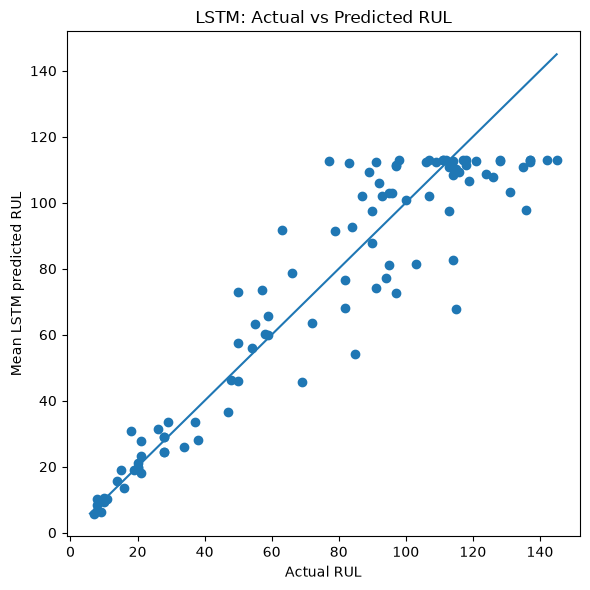

In [22]:
plt.figure(figsize=(6, 6))

plt.scatter(
    prediction_table["actual_RUL"],
    prediction_table["predicted_RUL_mean"]
)

minimum = min(
    prediction_table["actual_RUL"].min(),
    prediction_table["predicted_RUL_mean"].min()
)

maximum = max(
    prediction_table["actual_RUL"].max(),
    prediction_table["predicted_RUL_mean"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum]
)

plt.xlabel("Actual RUL")
plt.ylabel("Mean LSTM predicted RUL")
plt.title("LSTM: Actual vs Predicted RUL")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "lstm_actual_vs_predicted.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 22. Error for each engine


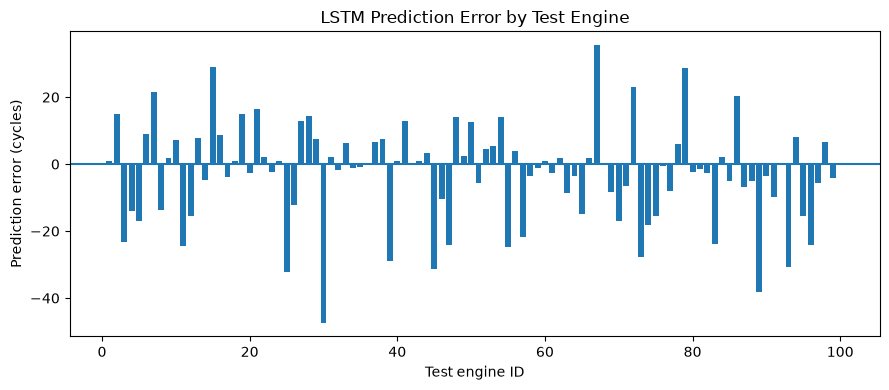

In [23]:
plt.figure(figsize=(9, 4))

plt.bar(
    prediction_table["unit"],
    prediction_table["error"]
)

plt.axhline(0)
plt.xlabel("Test engine ID")
plt.ylabel("Prediction error (cycles)")
plt.title("LSTM Prediction Error by Test Engine")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "lstm_error_by_engine.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 23. Largest errors

This table shows the test engines with the biggest absolute errors.


In [24]:
worst_errors = (
    prediction_table
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(15)
)

display(worst_errors)

,unit,last_observed_cycle,actual_RUL,predicted_RUL_mean,prediction_std,error,absolute_error
29,30,143,115.0,67.663185,5.780180,-47.336815,47.336815
88,89,177,136.0,97.895905,8.728723,-38.104095,38.104095
66,67,71,77.0,112.512581,1.520814,35.512581,35.512581
24,25,48,145.0,112.917992,1.991559,-32.082008,32.082008
44,45,152,114.0,82.722610,7.069273,-31.277390,31.277390
92,93,244,85.0,54.305271,2.240902,-30.694729,30.694729
14,15,76,83.0,112.046303,1.610884,29.046303,29.046303
38,39,37,142.0,113.012085,2.080239,-28.987915,28.987915
78,79,101,63.0,91.743065,19.586725,28.743065,28.743065
72,73,112,131.0,103.211174,9.270718,-27.788826,27.788826


## 24. Error by RUL range

I use the same RUL groups as the XGBoost notebook.


In [25]:
prediction_table["RUL_band"] = pd.cut(
    prediction_table["actual_RUL"],
    bins=[-np.inf, 30, 60, 90, 120, np.inf],
    labels=["0-30", "31-60", "61-90", "91-120", "121+"]
)

band_results = (
    prediction_table
    .groupby("RUL_band", observed=False)
    .agg(
        engines=("unit", "count"),
        MAE=("absolute_error", "mean"),
        mean_error=("error", "mean"),
        mean_prediction_std=("prediction_std", "mean")
    )
    .reset_index()
)

display(band_results)

,RUL_band,engines,MAE,mean_error,mean_prediction_std
0,0-30,25,2.530372,0.929357,1.049450
1,31-60,14,7.440061,2.064702,4.536495
2,61-90,15,16.955778,5.727523,8.417559
3,91-120,33,11.097055,-3.538894,5.163040
4,121+,13,22.804768,-22.804768,3.073105


## 25. Compare LSTM and XGBoost

The XGBoost notebook in this project produced:

- RMSE: **18.4838**
- MAE: **13.4419**

The LSTM comparison below uses these values.


In [26]:
XGBOOST_TEST_RMSE = 18.483829
XGBOOST_TEST_MAE = 13.441880

lstm_mean_rmse = seed_results["test_RMSE"].mean()
lstm_mean_mae = seed_results["test_MAE"].mean()

rmse_change_pct = (
    (XGBOOST_TEST_RMSE - lstm_mean_rmse)
    / XGBOOST_TEST_RMSE
    * 100
)

mae_change_pct = (
    (XGBOOST_TEST_MAE - lstm_mean_mae)
    / XGBOOST_TEST_MAE
    * 100
)

comparison = pd.DataFrame({
    "Model": [
        "XGBoost",
        f"LSTM mean ({len(seed_results)} seeds)"
    ],
    "Test_RMSE": [
        XGBOOST_TEST_RMSE,
        lstm_mean_rmse
    ],
    "Test_MAE": [
        XGBOOST_TEST_MAE,
        lstm_mean_mae
    ]
})

display(comparison)

print(
    f"RMSE improvement of LSTM over XGBoost: "
    f"{rmse_change_pct:.2f}%"
)

print(
    f"MAE improvement of LSTM over XGBoost: "
    f"{mae_change_pct:.2f}%"
)

,Model,Test_RMSE,Test_MAE
0,XGBoost,18.483829,13.441880
1,LSTM mean (3 seeds),16.061021,11.512125


RMSE improvement of LSTM over XGBoost: 13.11%
MAE improvement of LSTM over XGBoost: 14.36%


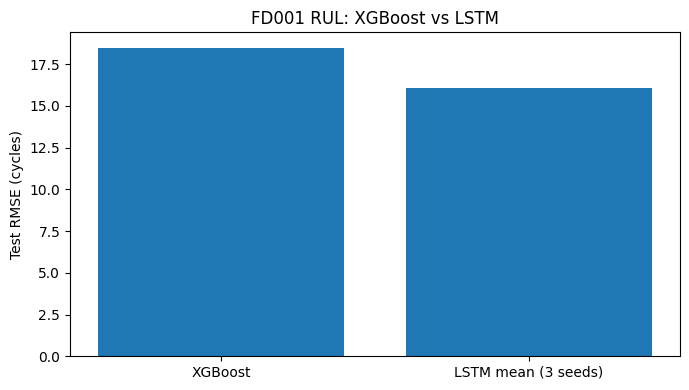

In [27]:
plt.figure(figsize=(7, 4))

positions = np.arange(len(comparison))

plt.bar(
    positions,
    comparison["Test_RMSE"]
)

plt.xticks(
    positions,
    comparison["Model"]
)

plt.ylabel("Test RMSE (cycles)")
plt.title("FD001 RUL: XGBoost vs LSTM")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "xgboost_vs_lstm_rmse.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 26. Save the results

The LSTM models, tables, settings and figures are saved in the output folder.


In [28]:
seed_results.to_csv(
    OUTPUT_DIR / "lstm_seed_results.csv",
    index=False
)

summary_metrics.to_csv(
    OUTPUT_DIR / "lstm_seed_summary.csv",
    index=False
)

prediction_table.to_csv(
    OUTPUT_DIR / "lstm_test_predictions.csv",
    index=False
)

band_results.to_csv(
    OUTPUT_DIR / "lstm_error_by_rul_band.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "xgboost_vs_lstm_comparison.csv",
    index=False
)

pd.DataFrame({
    "feature": sequence_features
}).to_csv(
    OUTPUT_DIR / "lstm_feature_list.csv",
    index=False
)

pd.DataFrame({
    "training_engine": fit_engines
}).to_csv(
    OUTPUT_DIR / "training_engine_ids.csv",
    index=False
)

pd.DataFrame({
    "validation_engine": val_engines
}).to_csv(
    OUTPUT_DIR / "validation_engine_ids.csv",
    index=False
)

config = {
    "rul_cap": RUL_CAP,
    "sequence_length": SEQUENCE_LENGTH,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "seeds": SEEDS,
    "sequence_features": sequence_features,
    "training_engine_count": len(fit_engines),
    "validation_engine_count": len(val_engines),
    "device": str(DEVICE),
    "pytorch_version": torch.__version__
}

with open(
    OUTPUT_DIR / "lstm_experiment_config.json",
    "w"
) as f:
    json.dump(config, f, indent=2)

print("Saved LSTM outputs to:", OUTPUT_DIR.resolve())

Saved LSTM outputs to: C:\Users\ak587\Downloads\New folder\lstm_outputs


## 27. LSTM project log

### Input and split

After removing the constant columns, I used **18 features** at each time step.

The sequence length was **30 cycles**.

The data produced:

- **14,241 training sequences**
- **3,490 validation sequences**
- **100 final test sequences**

I used the same **80 training engines** and **20 validation engines** as XGBoost.

The validation engine IDs were:

**1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84 and 91**

### Model

The LSTM had:
- one LSTM layer
- **64 hidden units**
- dropout **0.20**
- learning rate **0.001**
- batch size **256**
- **21,569 trainable parameters**

I ran it on **CPU** with seeds **42, 7 and 123**.

### Results for each seed

| Seed | Best epoch | Validation RMSE | Validation MAE | Test RMSE | Test MAE | Test R² | NASA score |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 42 | 52 | 14.1400 | 10.8033 | 16.1502 | 11.5150 | 0.8490 | 437.35 |
| 7 | 57 | 15.0588 | 10.9076 | 17.1196 | 12.2526 | 0.8303 | 426.40 |
| 123 | 50 | 14.4436 | 11.2709 | 14.9133 | 10.7688 | 0.8712 | 346.39 |

Training time was about **36.16 s**, **37.47 s** and **43.63 s** for the three runs.

### Mean result across the three runs

The mean test result was:

- RMSE: **16.0610 cycles**
- RMSE standard deviation: **1.1059**
- MAE: **11.5121 cycles**
- MAE standard deviation: **0.7419**
- R²: **0.8502**
- NASA score: **403.38**

The three runs were not identical, but they all beat the XGBoost RMSE and MAE from this notebook set.

### Averaged prediction

I also averaged the three predictions for each test engine.

That gave:

- RMSE: **14.9067 cycles**
- MAE: **10.8442 cycles**
- R²: **0.8713**
- NASA score: **308.77**

I keep this as an extra ensemble result. For the main single-model comparison I use the mean result across the three separate LSTM runs.

### Error by RUL range

Using the averaged prediction:

| True RUL | Engines | MAE | Mean error |
|---|---:|---:|---:|
| 0-30 | 25 | 2.53 | +0.93 |
| 31-60 | 14 | 7.44 | +2.06 |
| 61-90 | 15 | 16.96 | +5.73 |
| 91-120 | 33 | 11.10 | -3.54 |
| 121+ | 13 | 22.80 | -22.80 |

The LSTM was strongest in the **0-30** RUL group.

It still struggled in the **121+** group and usually predicted too little remaining life there.

### Biggest errors

Using the averaged prediction, the five largest absolute errors were:

- Engine 30: actual **115**, predicted **67.66**, absolute error **47.34**
- Engine 89: actual **136**, predicted **97.90**, absolute error **38.10**
- Engine 67: actual **77**, predicted **112.51**, absolute error **35.51**
- Engine 25: actual **145**, predicted **112.92**, absolute error **32.08**
- Engine 45: actual **114**, predicted **82.72**, absolute error **31.28**

### Comparison with XGBoost

XGBoost:

- RMSE: **18.4838**
- MAE: **13.4419**

Mean LSTM result across three seeds:

- RMSE: **16.0610**
- MAE: **11.5121**

Using these results, the mean LSTM improved RMSE by about **13.11%** and MAE by about **14.36%** compared with XGBoost.

The LSTM gave the better accuracy, but it took much longer to train.

### Main result

For this FD001 experiment, the LSTM performed better than XGBoost on both RMSE and MAE.

The LSTM was especially accurate when the real RUL was low, but high-RUL engines were still harder for both models.

This gives me a clear result for the model comparison: sequence modelling helped, but it also increased training time and model complexity.
